# New methods from the literature — robusta, nested leave-one-session-out

**Question:** can a method proven on linear NIR / hyperspectral data lower the error on unseen sessions?
**The shortlist was fixed before running** (from the literature search), and every method goes through the same
protocol as the final model: absorbance + offset, 1000–2450 nm, trimming and super-patches rebuilt inside each round
from the training sessions, inner leave-one-concentration-out with the one-standard-error rule for every setting,
error per dish on the held-out session, paired bootstrap for the verdicts.

| # | Method | Idea | Setting(s) tuned inside each round |
|---|---|---|---|
| ref | **PLSR** | the final model's method | latent variables |
| ref | **SVR (linear)** | best standard model on arabica | C |
| ref | **EMSC + PLSR** | best alternative on arabica | latent variables |
| 1 | **SO-PLS preprocessing ensemble** (SPORT-style; Roger, Biancolillo & Marini 2020) | four preprocessings of the same spectra — absorbance + offset, EMSC, SNV, first derivative — enter one model in turn; each block may add components only for what the earlier blocks missed | components per block, chosen block by block (0 allowed: a block that does not help is left out) |
| 2 | **EPO-PLSR** (External Parameter Orthogonalisation; Roger et al. 2003) | the differences between the three stirs of the same blend are pure nuisance (packing, surface). Their main directions are learned and projected out of every spectrum before PLSR | number of nuisance directions removed (0 = plain PLSR), latent variables |
| 3 | **VIP wavelength selection + PLSR** | keep only the wavelengths with VIP ≥ threshold, then PLSR. VIP is recomputed inside every inner fold, so selection never sees the dish it is tested on | threshold (0 = all bands), latent variables |
| 4 | **Joint robusta + arabica PLSR** | one model trained on both coffees (66 dishes instead of 33). Each coffee is centred on its own mean, so the coffee difference is removed and the shared chicory signal is learned from twice the dishes | latent variables |

Inner tuning uses spectra cleaned with the outer-round EMSC / EPO / centring basis (as for EMSC + PLSR before); the
held-out session never touches any of them. Outputs go to `new_methods_robusta/`.

## 1. Setup and data

In [1]:
import os
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from sklearn.cluster import KMeans
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore")

# ------------------------------- EDIT -------------------------------
COFFEE  = "robusta"                    # the coffee being evaluated: "robusta" or "arabica"
BASE    = Path(os.environ.get("COFFEE_DATA", "."))
OUT     = BASE / f"new_methods_{COFFEE}"
LEVELS_KEEP = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
WL_MIN, WL_MAX = 1000.0, 2450.0
TRIM_PCT, K_UNIT = 10, 8
N_BOOT = 2000
# ---------------------------------------------------------------------
OUT.mkdir(exist_ok=True, parents=True)
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
S_COLOR, S_MARKER = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}, {1: "o", 2: "s", 3: "^"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})


def load(coffee):
    if coffee == "robusta":
        old = pd.read_csv(BASE / "samples_out" / "training_samples.csv")
        new = pd.read_csv(BASE / "batch3_out" / "training_samples.csv")
        for c in ("scan", "group", "plate"):
            new[c] = new[c].astype(str) + "_b3"
        D, species = pd.concat([old, new], ignore_index=True), ["robusta", "robusta_chicory"]
    else:
        D, species = pd.read_csv(BASE / "arabica_out" / "arabica_chicory_all_sessions.csv"), ["arabica", "arabica_chicory"]
    D = D[D.species.isin(species) & (D.role == "calibration") & D.chicory_pct.isin(LEVELS_KEEP)].reset_index(drop=True)
    D["session"] = D["day"].astype(int)
    assert sorted(D.chicory_pct.unique()) == LEVELS_KEEP
    return D


def preprocess(R):
    R = np.clip(np.asarray(R, float), 1e-3, None)
    Z = np.log10(1.0 / R)
    return Z - Z.mean(-1, keepdims=True)


class Coffee:
    """One coffee's patches, with the final notebook's units() (trimming + super-patches) unchanged."""
    META = ["session", "capture", "label", "group", "chicory_pct", "patch_row", "patch_col"]
    def __init__(self, name):
        self.name, self.D = name, load(name)
        self.Z = preprocess(self.D[COLS].values)
        self.S, self.G = self.D.session.to_numpy(), self.D.group.astype(str).to_numpy()
        self.Y = self.D.chicory_pct.to_numpy(float)
        self._u = {}
    def units(self, train_sessions, k=K_UNIT):
        key = tuple(sorted(train_sessions))
        if key in self._u:
            return self._u[key]
        Z, GROUP = self.Z, self.G
        tr = np.isin(self.S, key)
        ref = PLSRegression(n_components=4).fit(Z[tr], self.Y[tr])
        mu = Z[tr].mean(0)
        T = (Z - mu) @ ref.x_rotations_
        q = np.sum(((Z - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
        keep = pd.Series(q).groupby(GROUP).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
        idx = []
        for g in pd.unique(GROUP):
            ii = np.where((GROUP == g) & keep)[0]
            if len(ii) < k:
                continue
            n = max(1, len(ii) // k)
            lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(
                self.D.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
            idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
        ZU = np.array([Z[i].mean(0) for i in idx])
        UM = self.D.iloc[[i[0] for i in idx]][self.META].reset_index(drop=True)
        self._u[key] = (ZU, UM)
        return ZU, UM


_tmp = load("robusta")
wc = [c for c in _tmp.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc])
BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]
OTHER = "arabica" if COFFEE == "robusta" else "robusta"
TGT, OTH = Coffee(COFFEE), Coffee(OTHER)
for c in (TGT, OTH):
    print(f"{c.name}: {len(c.D)} patches, {c.D.group.nunique()} dishes, sessions {sorted(c.D.session.unique())}")
print(f"evaluating {COFFEE}; {OTHER} is used only by the joint model")

robusta: 4910 patches, 33 dishes, sessions [np.int64(1), np.int64(2), np.int64(3)]
arabica: 4950 patches, 33 dishes, sessions [np.int64(1), np.int64(2), np.int64(3)]
evaluating robusta; arabica is used only by the joint model


## 2. Building blocks: the final notebook's tuning and scoring, plus the four new methods

In [2]:
def predict(model, X):
    return np.asarray(model.predict(X)).ravel()

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def plate_rmse(y, p, g):
    t = pd.DataFrame(dict(g=g, y=y, p=p)).groupby("g")[["y", "p"]].mean()
    return rmse(t.y, t.p)

def tune_any(build, grid, X, y, g, lev=None):
    """Inner leave-one-concentration-out, per-dish RMSE, one-standard-error rule (grid ordered simplest first)."""
    lev = y if lev is None else lev
    rows = []
    for prm in grid:
        fold = []
        for a, b in LeaveOneGroupOut().split(X, y, groups=lev):
            fold.append(plate_rmse(lev[b], predict(build(prm).fit(X[a], y[a]), X[b]) + (lev[b] - y[b]), g[b]))
        rows.append(dict(param=prm, mean=float(np.mean(fold)), se=float(np.std(fold, ddof=1) / np.sqrt(len(fold)))))
    T = pd.DataFrame(rows)
    best = int(T["mean"].idxmin())
    pick = int(np.flatnonzero(T["mean"].to_numpy() <= T.loc[best, "mean"] + T.loc[best, "se"])[0])
    return grid[pick], T.loc[pick, "mean"], T.loc[pick, "se"], T.loc[best, "mean"], T.loc[best, "se"]

LV_GRID = list(range(1, 13))
PLS  = lambda a: PLSRegression(n_components=a)
SVRL = lambda C: make_pipeline(StandardScaler(), SVR(kernel="linear", C=C))

# ---- EMSC (copied from the advanced-models notebook)
LAM = np.linspace(-1, 1, len(WL))
def emsc_fit(Ztr, ytr):
    m = Ztr.mean(0); yc = ytr - ytr.mean()
    k = yc @ (Ztr - m) / (yc @ yc)
    return dict(B=np.column_stack([np.ones_like(LAM), m, k, LAM, LAM ** 2]))
def emsc_apply(Zx, P):
    a, b, h, d, e = np.linalg.lstsq(P["B"], Zx.T, rcond=None)[0]
    return (Zx - a[:, None] - np.outer(d, LAM) - np.outer(e, LAM ** 2)) / b[:, None]

# ---- 1. SO-PLS preprocessing ensemble
BLOCKS = ["absorbance + offset", "EMSC", "SNV (of absorbance)", "first derivative (SG 15, 2)"]
SO_GRID = [LV_GRID, list(range(0, 9)), list(range(0, 9)), list(range(0, 9))]
def make_blocks(ZU, P):
    return [ZU, emsc_apply(ZU, P), ZU / ZU.std(1, keepdims=True), savgol_filter(ZU, 15, 2, deriv=1, axis=1)]

class SOPLS:
    def __init__(self, comps): self.comps = list(comps)
    def fit(self, Bs, y):
        self.mu = [B.mean(0) for B in Bs]
        self.sd = [np.where(B.std(0, ddof=1) > 1e-12, B.std(0, ddof=1), 1.0) for B in Bs]
        self.ym = y.mean(); yc = y - self.ym
        T = np.zeros((len(y), 0)); self.steps = []
        for B, mu, sd, a in zip(Bs, self.mu, self.sd, self.comps):
            if a == 0:
                self.steps.append(None); continue
            X = (B - mu) / sd
            C = np.linalg.lstsq(T, X, rcond=None)[0] if T.shape[1] else None
            if C is not None:
                X = X - T @ C                       # orthogonalise on everything the earlier blocks used
            pls = PLSRegression(n_components=a, scale=False).fit(X, yc)
            T = np.hstack([T, pls.transform(X)])
            self.steps.append((C, pls))
        self.b = np.linalg.lstsq(T, yc, rcond=None)[0]
        return self
    def predict(self, Bs):
        T = np.zeros((len(Bs[0]), 0))
        for B, mu, sd, st in zip(Bs, self.mu, self.sd, self.steps):
            if st is None:
                continue
            C, pls = st
            X = (B - mu) / sd
            if C is not None:
                X = X - T @ C
            T = np.hstack([T, pls.transform(X)])
        return T @ self.b + self.ym

class _Stack:                                # lets tune_any() slice a list of blocks like one matrix
    def __init__(self, Bs): self.Bs = Bs
    def __getitem__(self, i): return _Stack([B[i] for B in self.Bs])
    def __len__(self): return len(self.Bs[0])
    @property
    def shape(self): return self.Bs[0].shape

class _SOWrap:
    def __init__(self, comps): self.m = SOPLS(comps)
    def fit(self, S, y): self.m.fit(S.Bs, y); return self
    def predict(self, S): return self.m.predict(S.Bs)

def sopls_tune(Bs, y, g):
    comps = [0] * len(Bs)
    S = _Stack(Bs)
    for k in range(len(Bs)):
        grid = SO_GRID[k]
        def build(a, k=k):
            c = comps.copy(); c[k] = a; return _SOWrap(c)
        comps[k] = tune_any(build, grid, S, y, g)[0]
    return comps

# ---- 2. EPO: nuisance directions from the differences between stirs of the same blend
EPO_GRID = [0, 1, 2, 3, 4, 5, 6, 8]
def epo_basis(ZU, U, tr):
    d = pd.DataFrame(ZU[tr]).groupby(U.group[tr].to_numpy()).mean()
    info = U[tr].groupby("group")[["session", "label"]].first().loc[d.index]
    blend = (info.session.astype(str) + "|" + info.label).to_numpy()
    D = d.to_numpy() - d.groupby(blend).transform("mean").to_numpy()
    return np.linalg.svd(D, full_matrices=False)[2]      # rows: nuisance directions, strongest first
def epo_apply(Z, Vt, g):
    if g == 0:
        return Z
    P = Vt[:g].T
    return Z - (Z @ P) @ P.T

# ---- 3. VIP selection
VIP_T = [0.0, 0.8, 1.0, 1.2]
def vip_scores(p):
    W, T, Q = p.x_weights_, p.x_scores_, p.y_loadings_.ravel()
    ss = (Q ** 2) * (T ** 2).sum(0)
    return np.sqrt(W.shape[0] * ((W ** 2 / (W ** 2).sum(0)) @ ss) / ss.sum())
class VIPPLS:
    def __init__(self, a, t): self.a, self.t = a, t
    def fit(self, X, y):
        self.m = np.ones(X.shape[1], bool)
        if self.t > 0:
            v = vip_scores(PLSRegression(self.a).fit(X, y))
            self.m = v >= min(self.t, np.sort(v)[-2 * self.a])   # keep at least 2a bands
        self.p = PLSRegression(min(self.a, int(self.m.sum()))).fit(X[:, self.m], y)
        return self
    def predict(self, X): return predict(self.p, X[:, self.m])

def two_level_tune(outer_grid, make_X, inner_build, ytr, gtr):
    """Pick the outer setting (simplest first) by the one-standard-error rule over each setting's tuned LV."""
    res = []
    for o in outer_grid:
        lv, m, se, _, _ = tune_any(lambda a: inner_build(o, a), LV_GRID, make_X(o), ytr, gtr)
        res.append((o, lv, m, se))
    R = pd.DataFrame(res, columns=["o", "lv", "mean", "se"])
    b = int(R["mean"].idxmin())
    pick = int(np.flatnonzero(R["mean"].to_numpy() <= R.loc[b, "mean"] + R.loc[b, "se"])[0])
    return R.o[pick], int(R.lv[pick])

## 3. Nested leave-one-session-out

Takes several minutes. The reference rows must reproduce the earlier notebooks (robusta: PLSR 0.61 / 0.64 / 1.11,
linear SVR 0.83 mean, EMSC + PLSR 1.62 / 0.87 / 1.26).

In [3]:
MODELS = ["PLSR", "SVR (linear)", "EMSC + PLSR", "SO-PLS preprocessing ensemble", "EPO-PLSR", "VIP selection + PLSR",
          "Joint robusta + arabica PLSR"]
REFS = MODELS[:3]
rows, settings = [], []
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, U = TGT.units(train)
    tr, te = U.session.isin(train).to_numpy(), (U.session == held).to_numpy()
    ytr, gtr = U.chicory_pct[tr].to_numpy(float), U.group[tr].to_numpy()
    out, st = {}, dict(held_out=held)

    a, *_ = tune_any(PLS, LV_GRID, ZU[tr], ytr, gtr)
    out["PLSR"] = predict(PLS(a).fit(ZU[tr], ytr), ZU[te]); st["PLSR LV"] = a
    C, *_ = tune_any(SVRL, [.01, .1, 1, 10], ZU[tr], ytr, gtr)
    out["SVR (linear)"] = predict(SVRL(C).fit(ZU[tr], ytr), ZU[te]); st["SVR C"] = C
    P = emsc_fit(ZU[tr], ytr); Etr, Ete = emsc_apply(ZU[tr], P), emsc_apply(ZU[te], P)
    a, *_ = tune_any(PLS, LV_GRID, Etr, ytr, gtr)
    out["EMSC + PLSR"] = predict(PLS(a).fit(Etr, ytr), Ete); st["EMSC+PLSR LV"] = a

    # 1. SO-PLS
    Btr, Bte = make_blocks(ZU[tr], P), make_blocks(ZU[te], P)
    comps = sopls_tune(Btr, ytr, gtr)
    out["SO-PLS preprocessing ensemble"] = SOPLS(comps).fit(Btr, ytr).predict(Bte)
    st["SO-PLS comps per block"] = "/".join(map(str, comps))

    # 2. EPO
    Vt = epo_basis(ZU, U, tr)
    g_, a = two_level_tune(EPO_GRID, lambda g: epo_apply(ZU[tr], Vt, g), lambda g, a: PLS(a), ytr, gtr)
    out["EPO-PLSR"] = predict(PLS(a).fit(epo_apply(ZU[tr], Vt, g_), ytr), epo_apply(ZU[te], Vt, g_))
    st["EPO directions / LV"] = f"{g_} / {a}"

    # 3. VIP selection
    t_, a = two_level_tune(VIP_T, lambda t: ZU[tr], lambda t, a: VIPPLS(a, t), ytr, gtr)
    m = VIPPLS(a, t_).fit(ZU[tr], ytr)
    out["VIP selection + PLSR"] = m.predict(ZU[te])
    st["VIP threshold / LV / bands"] = f"{t_:g} / {a} / {int(m.m.sum())}"

    # 4. joint model: both coffees, each centred on its own training mean
    ZO, UO = OTH.units(train)
    tro = UO.session.isin(train).to_numpy()
    mT, mO = ZU[tr].mean(0), ZO[tro].mean(0)
    yo = UO.chicory_pct[tro].to_numpy(float)
    Xj = np.vstack([ZU[tr] - mT, ZO[tro] - mO])
    yj = np.concatenate([ytr - ytr.mean(), yo - yo.mean()])
    lev = np.concatenate([ytr, yo]); gj = np.concatenate([gtr, UO.group[tro].to_numpy()]).astype(str)
    a, *_ = tune_any(PLS, LV_GRID, Xj, yj, gj, lev=lev)
    out["Joint robusta + arabica PLSR"] = predict(PLS(a).fit(Xj, yj), ZU[te] - mT) + ytr.mean()
    st["Joint LV"] = a

    for name in MODELS:
        rows.append(pd.DataFrame(dict(model=name, fold=held, group=U.group[te].to_numpy(), label=U.label[te].to_numpy(),
                                      y=U.chicory_pct[te].to_numpy(float), p=out[name])))
    settings.append(st)
    print(f"session {held} held out done: " + ", ".join(f"{k} {v}" for k, v in st.items() if k != "held_out"))

PRED = pd.concat(rows, ignore_index=True)
SET = pd.DataFrame(settings)
print(); print(SET.to_string(index=False))

session 1 held out done: PLSR LV 6, SVR C 0.1, EMSC+PLSR LV 3, SO-PLS comps per block 6/0/0/0, EPO directions / LV 0 / 6, VIP threshold / LV / bands 0 / 6 / 266, Joint LV 8


session 2 held out done: PLSR LV 7, SVR C 1, EMSC+PLSR LV 5, SO-PLS comps per block 7/0/0/0, EPO directions / LV 5 / 5, VIP threshold / LV / bands 0 / 7 / 266, Joint LV 8


session 3 held out done: PLSR LV 6, SVR C 0.1, EMSC+PLSR LV 6, SO-PLS comps per block 6/0/0/0, EPO directions / LV 0 / 6, VIP threshold / LV / bands 0 / 6 / 266, Joint LV 7

 held_out  PLSR LV  SVR C  EMSC+PLSR LV SO-PLS comps per block EPO directions / LV VIP threshold / LV / bands  Joint LV
        1        6    0.1             3                6/0/0/0               0 / 6                0 / 6 / 266         8
        2        7    1.0             5                7/0/0/0               5 / 5                0 / 7 / 266         8
        3        6    0.1             6                6/0/0/0               0 / 6                0 / 6 / 266         7


## 4. Results and verdicts (paired bootstrap, dishes resampled within each held-out session)

In [4]:
def rmse_of(e): return float(np.sqrt(np.mean(np.square(e))))
dishes = {n: PRED[PRED.model == n].groupby(["fold", "group"], as_index=False).agg(y=("y", "first"), p=("p", "mean"))
          for n in MODELS}
PS = pd.DataFrame([dict(model=n, held_out=f, rmsep=rmse_of(d[d.fold == f].p - d[d.fold == f].y),
                        bias=float((d[d.fold == f].p - d[d.fold == f].y).mean()))
                   for n, d in dishes.items() for f in (1, 2, 3)])
RNG = np.random.default_rng(0)
def boot_vs(ref, name):
    a, b = dishes[ref], dishes[name]
    diff = np.zeros(N_BOOT)
    for f in (1, 2, 3):
        aa, bb = a[a.fold == f].sort_values("group"), b[b.fold == f].sort_values("group")
        ea, eb = (aa.p - aa.y).to_numpy() ** 2, (bb.p - bb.y).to_numpy() ** 2
        ii = RNG.integers(0, len(ea), size=(N_BOOT, len(ea)))
        diff += (np.sqrt(eb[ii].mean(1)) - np.sqrt(ea[ii].mean(1))) / 3
    return np.percentile(diff, [2.5, 97.5])

mean_of = PS.groupby("model").rmsep.mean()
BEST_REF = mean_of.loc[REFS].idxmin()
rows = []
for n in MODELS:
    s = PS[PS.model == n].set_index("held_out"); d = dishes[n]
    r = dict(model=n, S1=s.loc[1, "rmsep"], S2=s.loc[2, "rmsep"], S3=s.loc[3, "rmsep"], mean=s.rmsep.mean(),
             sd=s.rmsep.std(ddof=1), pooled=rmse_of(d.p - d.y), max_abs_bias=s.bias.abs().max())
    same = np.allclose(d.sort_values(["fold", "group"]).p.to_numpy(),
                       dishes[BEST_REF].sort_values(["fold", "group"]).p.to_numpy(), atol=1e-6)
    if n == BEST_REF:
        r.update(verdict="reference (best of the three)", ci="")
    elif same:
        r.update(verdict=f"identical to {BEST_REF} (tuning chose no change)", ci="")
    else:
        lo, hi = boot_vs(BEST_REF, n)
        r.update(verdict="better" if hi < 0 else "worse" if lo > 0 else "tie", ci=f"{lo:+.2f} to {hi:+.2f}")
    rows.append(r)
SUM = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(f"{COFFEE}: error per dish on the held-out session (% chicory); verdicts against {BEST_REF}")
print(SUM.round(2).to_string(index=False))

robusta: error per dish on the held-out session (% chicory); verdicts against PLSR
                        model   S1   S2   S3  mean   sd  pooled  max_abs_bias                                    verdict             ci
                         PLSR 0.61 0.64 1.11  0.79 0.28    0.88          0.47              reference (best of the three)               
                 SVR (linear) 0.66 0.78 1.06  0.83 0.21    0.91          0.19                                        tie -0.05 to +0.14
                  EMSC + PLSR 1.62 0.87 1.26  1.25 0.38    1.14          1.54                                      worse +0.30 to +0.64
SO-PLS preprocessing ensemble 0.61 0.64 1.11  0.79 0.28    0.88          0.47 identical to PLSR (tuning chose no change)               
                     EPO-PLSR 0.61 0.62 1.11  0.78 0.29    0.88          0.21                                        tie -0.09 to +0.07
         VIP selection + PLSR 0.61 0.64 1.11  0.79 0.28    0.88          0.47 identical to PLSR (tuni

## 5. Figure and saved results

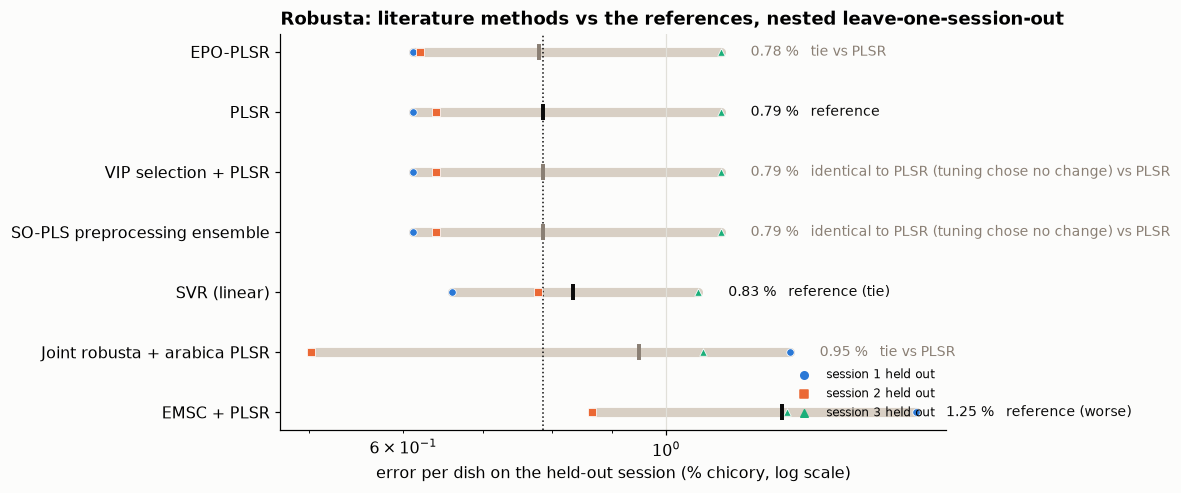

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/new_methods_robusta


In [5]:
order = SUM.sort_values("mean").model.tolist()
SI = SUM.set_index("model")
fig, ax = plt.subplots(figsize=(10.5, 4.6))
yy = np.arange(len(order))[::-1]
for yi, n in zip(yy, order):
    r = SI.loc[n]; v = PS[PS.model == n].sort_values("held_out")
    col = INK if n in REFS else ("#2a78d6" if r.verdict == "better" else "#a83b2a" if r.verdict == "worse" else "#8a7f74")
    ax.plot([v.rmsep.min(), v.rmsep.max()], [yi, yi], color="#d8cfc4", lw=6, solid_capstyle="round", zorder=1)
    for s_, e_ in zip(v.held_out, v.rmsep):
        ax.scatter(e_, yi, s=24, color=S_COLOR[s_], marker=S_MARKER[s_], zorder=3, edgecolor="white", linewidth=.5)
    ax.scatter(r["mean"], yi, s=120, marker="|", color=col, linewidth=2.6, zorder=4)
    lab = "reference" if n == BEST_REF else (f"{r.verdict} vs {BEST_REF}" if n not in REFS else f"reference ({r.verdict})")
    ax.text(v.rmsep.max() * 1.06, yi, f"{r['mean']:.2f} %   {lab}", va="center", fontsize=9, color=col)
ax.set_yticks(yy, order); ax.set_xscale("log")
ax.set_xlabel("error per dish on the held-out session (% chicory, log scale)")
ax.axvline(SI.loc[BEST_REF, "mean"], color=INK, ls=":", lw=1)
for s_ in (1, 2, 3):
    ax.scatter([], [], color=S_COLOR[s_], marker=S_MARKER[s_], s=24, label=f"session {s_} held out")
ax.legend(loc="lower right", fontsize=8); ax.grid(axis="y", visible=False)
ax.set_title(f"{COFFEE.capitalize()}: literature methods vs the references, nested leave-one-session-out",
             loc="left", fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "01_new_methods.png", bbox_inches="tight"); plt.show()

SUM.to_csv(OUT / "model_summary.csv", index=False)
PS.to_csv(OUT / "per_session.csv", index=False)
PRED.to_csv(OUT / "heldout_predictions.csv", index=False)
SET.to_csv(OUT / "settings_per_round.csv", index=False)
print("saved to", OUT)